# EDA — Global Superstore (2011–2014)

Quick exploration to decide what belongs on the **Regional Profit Watch** dashboard.
One row = one order line item (product × order). 51,290 rows, 24 columns,
Jan 2011 – Dec 2014, Kaggle snapshot (synthetic Tableau sample data).

**Questions we need answered before designing the dashboard:**
1. What is the overall shape of sales and profit, and how do they move over time?
2. Where does profit leak (which sub-categories, at which discount levels)?
3. What is missing or misleading in this data?

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

df = pd.read_csv("data/superstore.csv", parse_dates=["Order Date", "Ship Date"])
df.head(3)

,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,City,State,Country,...,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Shipping Cost,Order Priority
0,CA-2012-124891,2012-07-31,2012-07-31,Same Day,RH-19495,Rick Hansen,Consumer,New York City,New York,United States,...,TEC-AC-10003033,Technology,Accessories,Plantronics CS510 - Over-the-Head monaural Wir...,"2,309.65",7,0.00,762.18,933.57,Critical
1,IN-2013-77878,2013-02-05,2013-02-07,Second Class,JR-16210,Justin Ritter,Corporate,Wollongong,New South Wales,Australia,...,FUR-CH-10003950,Furniture,Chairs,"Novimex Executive Leather Armchair, Black","3,709.39",9,0.10,-288.76,923.63,Critical
2,IN-2013-71249,2013-10-17,2013-10-18,First Class,CR-12730,Craig Reiter,Consumer,Brisbane,Queensland,Australia,...,TEC-PH-10004664,Technology,Phones,"Nokia Smart Phone, with Caller ID","5,175.17",9,0.10,919.97,915.49,Medium


## 1. Structure and data quality

Shape, data types, missing values, and the time coverage. A partial final month would
make the latest trend point misleading, so we check that every month is complete.

In [2]:
print(f"rows={len(df):,}  orders={df['Order ID'].nunique():,}  customers={df['Customer ID'].nunique():,}")
print(f"date range: {df['Order Date'].min():%Y-%m-%d} -> {df['Order Date'].max():%Y-%m-%d}")
print(f"months covered: {df['Order Date'].dt.to_period('M').nunique()}")

missing = df.isna().sum()
print("\nmissing values:"); print(missing[missing > 0])
print(f"\nPostal Code non-missing only for US rows: "
      f"{df[df['Postal Code'].notna()]['Market'].unique().tolist()}")

rows=51,290  orders=25,035  customers=1,590
date range: 2011-01-01 -> 2014-12-31
months covered: 48

missing values:
Postal Code    41296
dtype: int64

Postal Code non-missing only for US rows: ['US']


In [3]:
monthly_rows = df.set_index("Order Date").resample("ME").size()
print(f"months with < 200 rows: {(monthly_rows < 200).sum()} of {len(monthly_rows)}  (no partial months)")

df[["Sales", "Quantity", "Discount", "Profit", "Shipping Cost"]].describe()

months with < 200 rows: 0 of 48  (no partial months)


,Sales,Quantity,Discount,Profit,Shipping Cost
count,"51,290.00","51,290.00","51,290.00","51,290.00","51,290.00"
mean,246.49,3.48,0.14,28.61,26.38
std,487.57,2.28,0.21,174.34,57.30
min,0.44,1.00,0.00,"-6,599.98",0.00
25%,30.76,2.00,0.00,0.00,2.61
50%,85.05,3.00,0.00,9.24,7.79
75%,251.05,5.00,0.20,36.81,24.45
max,"22,638.48",14.00,0.85,"8,399.98",933.57


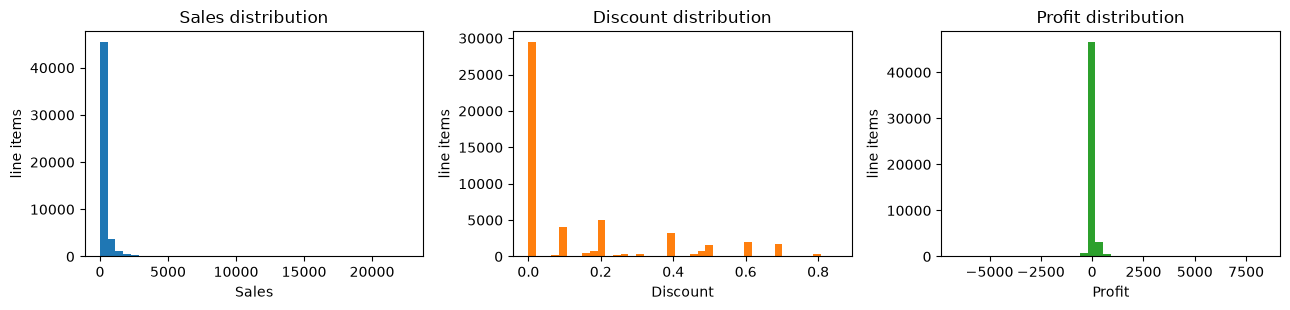

Sales skewness 8.1 | Profit skewness 4.2
discount: 57% of lines at 0%, deepest 85%
lines sold at >=30% discount: 20.9%


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, col, color in zip(axes, ["Sales", "Discount", "Profit"], ["#1f77b4", "#ff7f0e", "#2ca02c"]):
    ax.hist(df[col], bins=40, color=color)
    ax.set_title(f"{col} distribution")
    ax.set_xlabel(col)
    ax.set_ylabel("line items")
fig.tight_layout()
plt.show()

print(f"Sales skewness {df['Sales'].skew():.1f} | Profit skewness {df['Profit'].skew():.1f}")
print(f"discount: {(df['Discount'] == 0).mean():.0%} of lines at 0%, deepest {df['Discount'].max():.0%}")
print(f"lines sold at >=30% discount: {(df['Discount'] >= 0.3).mean():.1%}")

**Findings:** 51,290 line items across 25,035 orders and 1,590 customers; all 48 months are
complete (no partial-month trap). Only `Postal Code` has missing values (81% missing — it is
populated for US rows only), so city/postal-level geography is unusable outside the US.
`Sales` (skew 8.1) and `Profit` (skew 4.2) are heavily right-skewed — a handful of very large
lines dominate the totals, so the dashboard must never show "the average order". Discount is a
different animal: it clusters at round policy levels (57% of lines carry no discount at all, then
10/20/30/40% spikes, with a few in-between values), which is why bucketing it by depth is
meaningful and why 20.9% of lines fall into the ≥30% "deep discount" band.

## 2. Headline numbers and time trend

In [5]:
sales, profit = df["Sales"].sum(), df["Profit"].sum()
print(f"total sales  : ${sales:,.0f}")
print(f"total profit : ${profit:,.0f}")
print(f"margin       : {profit/sales:.1%}")
print(f"loss-making line items: {(df['Profit'] < 0).mean():.1%}")

monthly = df.set_index("Order Date").resample("ME").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
yearly = df.groupby(df["Order Date"].dt.year).agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
yearly["Margin"] = yearly["Profit"] / yearly["Sales"]
yearly

total sales  : $12,642,502
total profit : $1,467,457
margin       : 11.6%
loss-making line items: 24.5%


,Sales,Profit,Margin
Order Date,,,
2011,"2,259,450.90","248,940.81",0.11
2012,"2,677,438.69","307,415.28",0.11
2013,"3,405,746.45","406,935.23",0.12
2014,"4,299,865.87","504,165.97",0.12


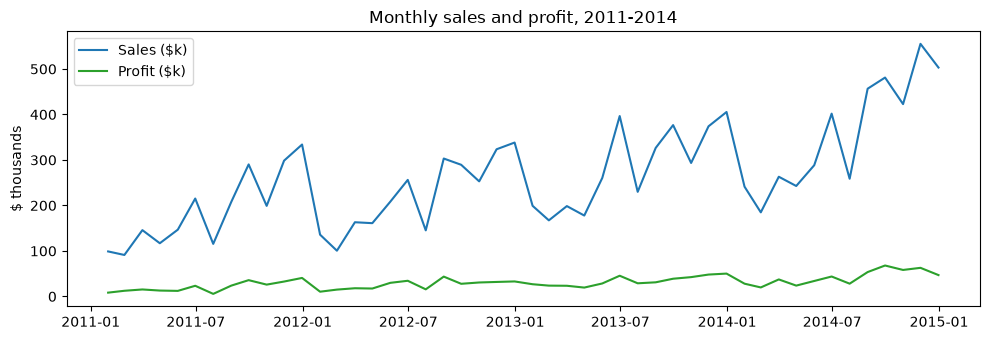

In [6]:
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(monthly.index, monthly["Sales"] / 1e3, label="Sales ($k)", color="#1f77b4")
ax.plot(monthly.index, monthly["Profit"] / 1e3, label="Profit ($k)", color="#2ca02c")
ax.set_title("Monthly sales and profit, 2011-2014")
ax.set_ylabel("$ thousands")
ax.legend()
fig.tight_layout(); plt.show()

**Findings:** steady growth (sales roughly double 2011 -> 2014), margin stable at ~11-12%,
clear Q4 seasonality. Monthly profit is positive in every single month for the company as a
whole — losses hide *inside* the totals, which is exactly why the manager needs a breakdown.

## 3. Where profit leaks: discounts

The dataset's most decision-relevant relationship. We bucket line items by discount depth
and look at the resulting margin.

In [7]:
buckets = pd.cut(df["Discount"], [-0.01, 0.001, 0.1, 0.2, 0.3, 0.4, 1.0],
                labels=["0%", "(0,10%]", "(10,20%]", "(20,30%]", "(30,40%]", ">40%"])
d = df.assign(bucket=buckets).groupby("bucket", observed=True).agg(
    lines=("Profit", "size"), Sales=("Sales", "sum"), Profit=("Profit", "sum"))
d["Margin"] = d["Profit"] / d["Sales"]
d

,lines,Sales,Profit,Margin
bucket,,,,
0%,29009,"6,992,410.95","1,770,695.27",0.25
"(0,10%]",4679,"1,962,618.85","338,189.26",0.17
"(10,20%]",6274,"1,757,261.34","173,254.84",0.10
"(20,30%]",967,"382,554.69","-21,155.61",-0.06
"(30,40%]",3400,"701,343.12","-166,115.45",-0.24
>40%,6961,"846,312.97","-627,411.02",-0.74


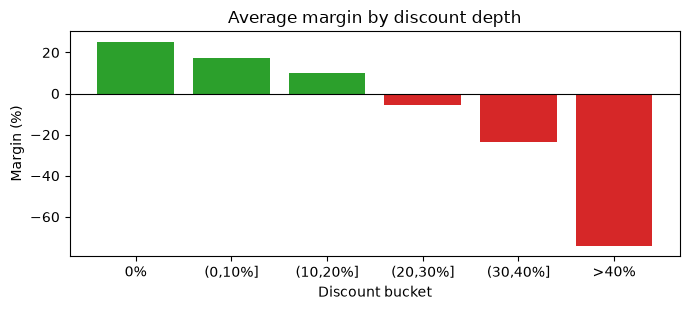

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(d.index.astype(str), d["Margin"] * 100, color=["#2ca02c", "#2ca02c", "#2ca02c", "#d62728", "#d62728", "#d62728"])
ax.axhline(0, color="black", lw=0.8)
ax.set_title("Average margin by discount depth")
ax.set_xlabel("Discount bucket"); ax.set_ylabel("Margin (%)")
fig.tight_layout(); plt.show()

**Findings — the core insight:** margin collapses as discount depth rises. Lines sold at
**0% discount earn ~26% margin; lines sold above 30% discount are sold at a loss** (below 30%
discount share of sales is small, but those lines destroy ~$0.79M of profit over four years).
This is a controllable lever: discounts are approved by someone, so this is what the dashboard
should surface.

## 4. Sub-category view

In [9]:
sc = df.groupby("Sub-Category").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
sc["Margin"] = sc["Profit"] / sc["Sales"]
sc = sc.sort_values("Profit")
deep = df[df["Discount"] >= 0.3].groupby("Sub-Category")["Profit"].sum().rename("Profit@>=30% disc")
sc = sc.join(deep).fillna(0)
sc.style.format({"Sales": "${:,.0f}", "Profit": "${:,.0f}", "Margin": "{:.1%}", "Profit@>=30% disc": "${:,.0f}"})

,Sales,Profit,Margin,Profit@>=30% disc
Sub-Category,,,,
Tables,"$757,042","$-64,083",-8.5%,"$-132,541"
Fasteners,"$83,242","$11,525",13.8%,"$-6,001"
Labels,"$73,404","$15,011",20.4%,"$-3,570"
Supplies,"$243,074","$22,583",9.3%,"$-14,703"
Envelopes,"$170,904","$29,601",17.3%,"$-10,427"
Furnishings,"$385,578","$46,967",12.2%,"$-25,123"
Art,"$372,092","$57,954",15.6%,"$-19,842"
Machines,"$779,060","$58,868",7.6%,"$-71,799"
Paper,"$244,292","$59,208",24.2%,"$-9,825"


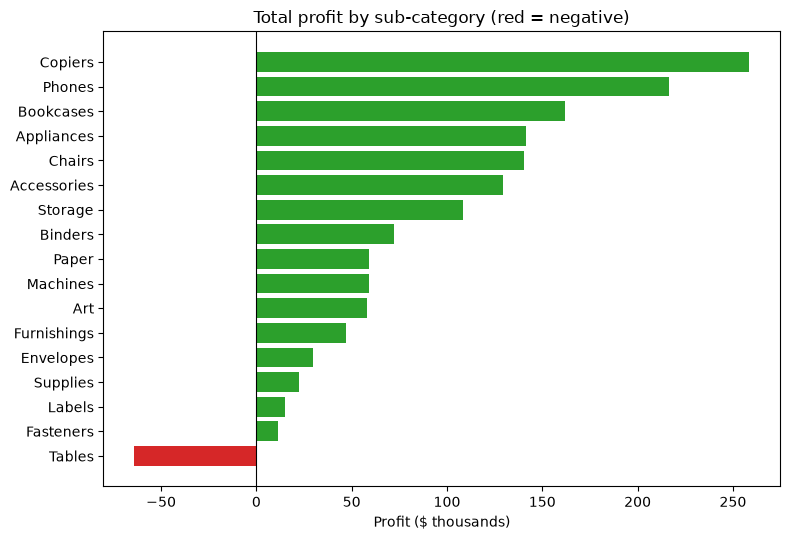

In [10]:
fig, ax = plt.subplots(figsize=(8, 5.5))
colors = ["#d62728" if p < 0 else "#2ca02c" for p in sc["Profit"]]
ax.barh(sc.index, sc["Profit"] / 1e3, color=colors)
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Total profit by sub-category (red = negative)")
ax.set_xlabel("Profit ($ thousands)")
fig.tight_layout(); plt.show()

**Findings:** `Tables` is the only sub-category that loses money overall (-$64k, -8.5% margin),
and most of that loss comes from deep-discount lines. Copiers, Phones and Bookcases are the
profit engines. A ranked sub-category bar immediately shows the manager where to look.

## 5. Returns and other traps

In [11]:
returns = pd.read_csv("data/returns.csv")
returned_orders = set(returns["Order ID"])
share = df["Order ID"].isin(returned_orders).mean()
print(f"orders returned: {returns.shape[0]:,}  |  share of line items on a returned order: {share:.1%}")
print("Returns table has no line-level detail and no refund amounts -> dashboard totals are gross, not net.")

orders returned: 1,173  |  share of line items on a returned order: 5.9%
Returns table has no line-level detail and no refund amounts -> dashboard totals are gross, not net.


**Findings:** ~5.9% of line items sit on returned orders, but the Returns table carries no
amounts, so sales/profit cannot be netted down. The dashboard must state this.

## 6. What goes on the dashboard (decision)

| Element | In / Out | Why |
|---|---|---|
| KPIs: Sales, Profit, Margin (vs prior year) | **In** | The "is anything wrong" answer in 5 seconds |
| Monthly sales & profit trend | **In** | Explains *when* a headline number moved; shows Q4 seasonality |
| Profit by sub-category, split by discount depth | **In** | Explains *why*: one glance shows losses sit in deep-discount lines |
| Filters: Market, Region, Year range | **In** | A regional manager looks at *their* region, not the world |
| Shipping cost / ship mode analysis | **Out** | Interesting in EDA, but the manager cannot act on it between monthly reviews |
| Customer leaderboard / segment split | **Out** | That is a marketing question with a different owner; synthetic names add no decision value |
| Country/city map | **Out** | Postal codes exist only for the US; region-level rollup already answers the question |

**Known traps handled in the app:** totals are gross of returns (~5.9% of orders), data is a
synthetic snapshot (labeled on the page), and every month is complete so the trend has no
partial-month artifact.